# Reto 1 - Exploracion y calidad de datos
## Mercedes-Benz Malackathon 2026

**Equipo:** Recreativo de WHERE V=A  

---

En este notebook vamos a realizar un analisis exploratorio de datos (EDA) completo sobre el dataset
de clientes de Mercedes-Benz. El dataset contiene aproximadamente 300.000 registros con 39 columnas
que integran informacion de distintas dimensiones: perfil demografico, caracteristicas del vehiculo,
relacion con la marca, consentimientos de comunicacion y poder adquisitivo por zona geografica.

El objetivo de este reto es:
1. Obtener una vision general de los datos mediante estadisticas descriptivas
2. Analizar los valores nulos y proponer un tratamiento justificado
3. Visualizar las distribuciones de las variables mas relevantes
4. Identificar y excluir columnas que no aportan valor analitico (indices, metadatos, identificadores)
5. Detectar problemas de calidad como multicolinealidad o inconsistencias

Al final exportaremos el dataset limpio para que sea directamente utilizable en el Reto 2 (Feature Engineering).

---
## 1. Carga de librerias y configuracion inicial

Importamos las librerias que vamos a necesitar a lo largo de todo el analisis.
Configuramos tambien el estilo de los graficos para que sean consistentes en todo el notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# Configuracion visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
warnings.filterwarnings('ignore')

# Semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Crear carpeta de figuras si no existe
os.makedirs('figures', exist_ok=True)

# Fecha de referencia para calculos de antiguedad del vehiculo
REFERENCE_DATE = pd.Timestamp('2026-10-15')

print('Librerias cargadas correctamente')
print(f'Fecha de referencia: {REFERENCE_DATE.strftime("%Y-%m-%d")}')

Librerias cargadas correctamente
Fecha de referencia: 2026-10-15


---
## 2. Carga del dataset y primera inspeccion

Cargamos el CSV y echamos un primer vistazo a las dimensiones, tipos de datos y primeras filas
para hacernos una idea general de con que estamos trabajando.

In [3]:
DATA_PATH = 'datos_reto_mercedes_benz_malackathon.csv'

df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print(f'Dimensiones del dataset: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')
df_raw.head()

Dimensiones del dataset: 302,850 filas x 39 columnas


,Unnamed: 0,client_id,vehicle_id,age_range,gender_derived,model_series,vehicle_type,model_class,product_group,engine_concept,...,trip_distance_median,trip_distance_all_counter,operating_hours_total,fuel_consumption_average,speed_average,speed_mode,speed_median,speed_all_counter,number_of_households,purchasing_power_millions_eur
0,0,000144e39c02702f821f69beeb7036f40cf8505051050f...,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,35-44,female,177,A 180 d,A-Class,P,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55298.0,3301.589
1,1,000144e39c02702f821f69beeb7036f40cf8505051050f...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,35-44,female,206,C 200 d,C-Class,P,NaN,...,7.5,1305.0,295.98,6.61,40.34,30,30.0,1066745.6,55298.0,3301.589
2,2,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...,25-34,male,213,AMG E 63 S 4MATIC+,E-Class,P,COMBUSTION,...,NaN,NaN,964.89,12.59,NaN,NaN,NaN,NaN,2712.0,222.002
3,3,00046586c51084441db2d37ad19472cda98a6552323fab...,8097810bd618668fd1f23ff9827fc519d53b3672386ef5...,65+,male,447,V 300AVG/L4X2 3200,V-Class / Vito,T,COMBUSTION,...,3.0,102.0,48.13,8.78,70.62,110,75.0,175494.3,6394.0,468.152
4,4,0005e6cc04ecf053522bdce2336695e8a28b3205f6ee76...,200a00413abffb67d9d3b488c340898d7c829115b94569...,35-44,male,254,GLC 300 de 4MATIC,GLC-Class,P,PLUGIN_HYBRID,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9724.0,591.830


Veamos los tipos de datos de cada columna y cuantos valores unicos tiene cada una.
Esto nos va a ayudar a clasificar las variables en categoricas, numericas, booleanas, etc.

In [6]:
info_df = pd.DataFrame({
    'Tipo': df_raw.dtypes,
    'No_Nulos': df_raw.notnull().sum(),
    'Nulos': df_raw.isnull().sum(),
    'Pct_Nulos': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'Valores_Unicos': df_raw.nunique()
})
info_df = info_df.sort_values('Pct_Nulos', ascending=False)
print(info_df.to_string())

                                        Tipo  No_Nulos   Nulos  Pct_Nulos  Valores_Unicos
trip_distance_average                float64    116993  185857      61.37            5476
speed_average                        float64    120468  182382      60.22            8248
speed_all_counter                    float64    121691  181159      59.82          117441
speed_mode                               str    121691  181159      59.82              17
speed_median                         float64    121691  181159      59.82              12
fuel_consumption_average             float64    122125  180725      59.67            2267
trip_distance_all_counter            float64    123020  179830      59.38           10780
trip_distance_median                 float64    123020  179830      59.38              13
trip_distance_mode                       str    123020  179830      59.38             108
fuel_type                                str    124105  178745      59.02               7
operating_

Podemos apreciar que 12 de las características contienen más del 50% de valores nulos, lo cual debemos de tratar sí o sí. 

Antes de meternos en el detalle, vamos a organizar las 39 columnas por bloques tematicos.
Esto nos permite entender la estructura del dataset y planificar mejor el analisis.

| Bloque | Columnas | Descripcion |
|--------|----------|-------------|
| Identificadores | `Unnamed: 0`, `client_id`, `vehicle_id` | Indices y hashes sin valor analitico |
| Vehiculo | `model_series`, `vehicle_type`, `model_class`, `engine_concept`, `fuel_type`, `product_group`, `date_of_first_registration`, `is_current_vehicle` | Caracteristicas del coche |
| Cliente | `age_range`, `gender_derived`, `role`, `role_type`, `months_as_mb_customer`, `currently_connected_vehicles`, `finance_leasing_status`, `workshop_visits_warranty_goodwill` | Perfil y relacion con la marca |
| Consentimientos | `consent_phone_communication_channel`, `consent_epost_communication_channel`, `consent_post_communication_channel` | Permisos de contacto |
| Socioeconomico | `purchasing_power_per_inhabitant_eur`, `purchasing_power_per_household_eur`, `purchasing_power_millions_eur`, `population`, `number_of_households`, `zipcode` | Datos de la zona geografica |
| Telemetria | `trip_distance_*`, `speed_*`, `fuel_consumption_average`, `operating_hours_total` | Datos de conduccion conectada |

Como primera observación, notamos que los identificadores no nos servirán para nuestro análisis, ya que no aportan valor al entrenamiento. Para cada uno de estos bloques que hemos definido, vemos el porcentaje de nulos presente:

In [7]:
# Calculamos la nulidad media por cada bloque tematico

bloques = {
    'Vehiculo': ['model_series', 'vehicle_type', 'model_class', 'engine_concept',
                 'fuel_type', 'product_group', 'date_of_first_registration', 'is_current_vehicle'],
    'Cliente': ['age_range', 'gender_derived', 'role', 'role_type',
                'months_as_mb_customer', 'currently_connected_vehicles',
                'finance_leasing_status', 'workshop_visits_warranty_goodwill'],
    'Consentimientos': ['consent_phone_communication_channel',
                        'consent_epost_communication_channel',
                        'consent_post_communication_channel'],
    'Socioeconomico': ['purchasing_power_per_inhabitant_eur', 'purchasing_power_per_household_eur',
                       'purchasing_power_millions_eur', 'population', 'number_of_households', 'zipcode'],
    'Telemetria': [c for c in df_raw.columns if any(k in c for k in ['trip_', 'speed_', 'fuel_', 'operating_'])]
}

print('Nulidad media por bloque tematico:')
print('-' * 50)
for nombre, cols in bloques.items():
    existentes = [c for c in cols if c in df_raw.columns]
    nulidad_media = df_raw[existentes].isnull().mean().mean() * 100
    print(f'  {nombre:20s}: {len(existentes)} variables, nulidad media = {nulidad_media:.1f}%')

Nulidad media por bloque tematico:
--------------------------------------------------
  Vehiculo            : 8 variables, nulidad media = 13.3%
  Cliente             : 8 variables, nulidad media = 1.4%
  Consentimientos     : 3 variables, nulidad media = 0.0%
  Socioeconomico      : 6 variables, nulidad media = 6.1%
  Telemetria          : 11 variables, nulidad media = 59.6%


Podemos observar que la categoría principal en la que tenemos más nulos es Telemetría, lo cual puede pasar debido a la presencia de coches antiguos en los que no se emitían estos datos. Veremos más adelante como tratamos estos nulos. 

---
## 3. Estadisticas descriptivas de las variables principales

### 3.1 Variables numericas

Empezamos con las estadisticas clasicas (media, mediana, desviacion tipica, etc.) de todas las columnas
numericas del dataset. Esto nos da una idea de las escalas, rangos y posibles valores atipicos.

In [8]:
# Excluimos Unnamed: 0 que es solo un indice
numericas = df_raw.select_dtypes(include=[np.number]).columns.tolist()
numericas = [c for c in numericas if c != 'Unnamed: 0']

print(f'Variables numericas encontradas: {len(numericas)}')
print()
df_raw[numericas].describe().T.round(2)

Variables numericas encontradas: 17



,count,mean,std,min,25%,50%,75%,max
model_series,302850.0,267.88,150.21,107.00,177.00,243.00,254.00,9.100000e+02
months_as_mb_customer,302846.0,43.87,26.89,0.00,25.00,39.00,60.00,1.200000e+02
currently_connected_vehicles,302850.0,2.15,3.53,0.00,1.00,1.00,2.00,2.100000e+01
workshop_visits_warranty_goodwill,302850.0,1.75,2.43,0.00,0.00,1.00,3.00,4.400000e+01
purchasing_power_per_inhabitant_eur,283763.0,46481.17,17294.53,19701.53,31518.15,46165.64,54210.68,1.483537e+05
purchasing_power_per_household_eur,283763.0,104766.27,41597.55,45087.34,71961.82,102246.51,122300.85,3.424980e+05
population,283836.0,19664.85,36803.22,0.00,3135.00,7132.00,17625.00,2.207940e+05
trip_distance_average,116993.0,16.16,10.67,1.00,10.15,14.02,19.53,3.000000e+02
trip_distance_median,123020.0,6.62,7.77,1.00,3.00,7.50,7.50,3.000000e+02
trip_distance_all_counter,123020.0,2351.70,2768.20,0.00,518.00,1593.00,3321.00,8.907800e+04


De aquí sacamos varias conclusiones:
* model_series no debe tratarse como variable numérica continua: Aunque aparece con tipo flotante (media de 267.88), el diccionario de datos indica que es un código alfanumérico que representa la serie del modelo.
* months_as_mb_customer tiene un valor máximo clavado en 120.0 meses (10 años). Los valores superiores han sido truncados en la extracción. Así, nuestra categoría de clientes fieles será aquella que ronde los 8-9 años de antiguedad. 
* El poder adquisitivo medio por habitante en la zona de residencia es de 46.481 € y el poder adquisitivo por hogar supera los 104.766 €. Por tanto, en Suiza y Austria tenemos personas con gran poder adquisitivo. 

### 3.2 Variables categoricas

Para las variables categoricas nos interesa saber cuantas categorias tiene cada una y cual es la mas frecuente.
Esto nos permite detectar variables con demasiadas categorias (que seran problematicas para codificar)
o con muy pocas (que podrian ser binarias).

In [9]:
categoricas = df_raw.select_dtypes(include=['object', 'bool']).columns.tolist()
categoricas = [c for c in categoricas if c not in ['client_id', 'vehicle_id', 'Unnamed: 0']]

print(f'Variables categoricas/booleanas: {len(categoricas)}')
print('=' * 70)

for col in categoricas:
    n_unique = df_raw[col].nunique()
    top_val = df_raw[col].mode().iloc[0] if not df_raw[col].mode().empty else 'N/A'
    top_freq = df_raw[col].value_counts().iloc[0] if df_raw[col].notnull().any() else 0
    nulos = df_raw[col].isnull().sum()
    print(f'  {col:45s} | categorias: {n_unique:>5} | moda: {str(top_val):>20s} ({top_freq:>7,}) | nulos: {nulos:>7,}')

Variables categoricas/booleanas: 19
  age_range                                     | categorias:     6 | moda:                45-54 ( 68,253) | nulos:       0
  gender_derived                                | categorias:     2 | moda:                 male (223,091) | nulos:  33,923
  vehicle_type                                  | categorias:  1436 | moda:     GLC 220 d 4MATIC ( 10,656) | nulos:     922
  model_class                                   | categorias:    42 | moda:            GLC-Class ( 44,198) | nulos:   3,369
  product_group                                 | categorias:     4 | moda:                    P (255,604) | nulos:       0
  engine_concept                                | categorias:     4 | moda:           COMBUSTION ( 98,424) | nulos: 134,390
  country_code                                  | categorias:     2 | moda:                   CH (192,878) | nulos:       0
  fuel_type                                     | categorias:     7 | moda:               DIESEL

Resaltamos los siguientes detalles:
* date_of_first_registration NO es categórica. Debemos transformarla a formato date o bien sustituir por la edad del vehículo (desde su registro). 
* trip_distance_mode y speed_mode son magnitudes físicas continuas/discretas: Aunque están registradas como string, representan valores de distancia (km) y velocidad (km/h)
* Debemos descartar vehicle_type del clustering debido a su alta cardinalidad, usando niveles superiores de abstraccion como model_class. 

---
## 4. Analisis detallado de valores nulos

Vamos a hacer un mapa completo de los nulos,
visualizarlo y proponer una estrategia de tratamiento para cada columna.

### 4.1 Mapa de nulidad y tabla resumen

Generamos un mapa de calor que muestra donde estan los nulos en el dataset.
A la derecha, un grafico de barras con el porcentaje de nulos por columna.

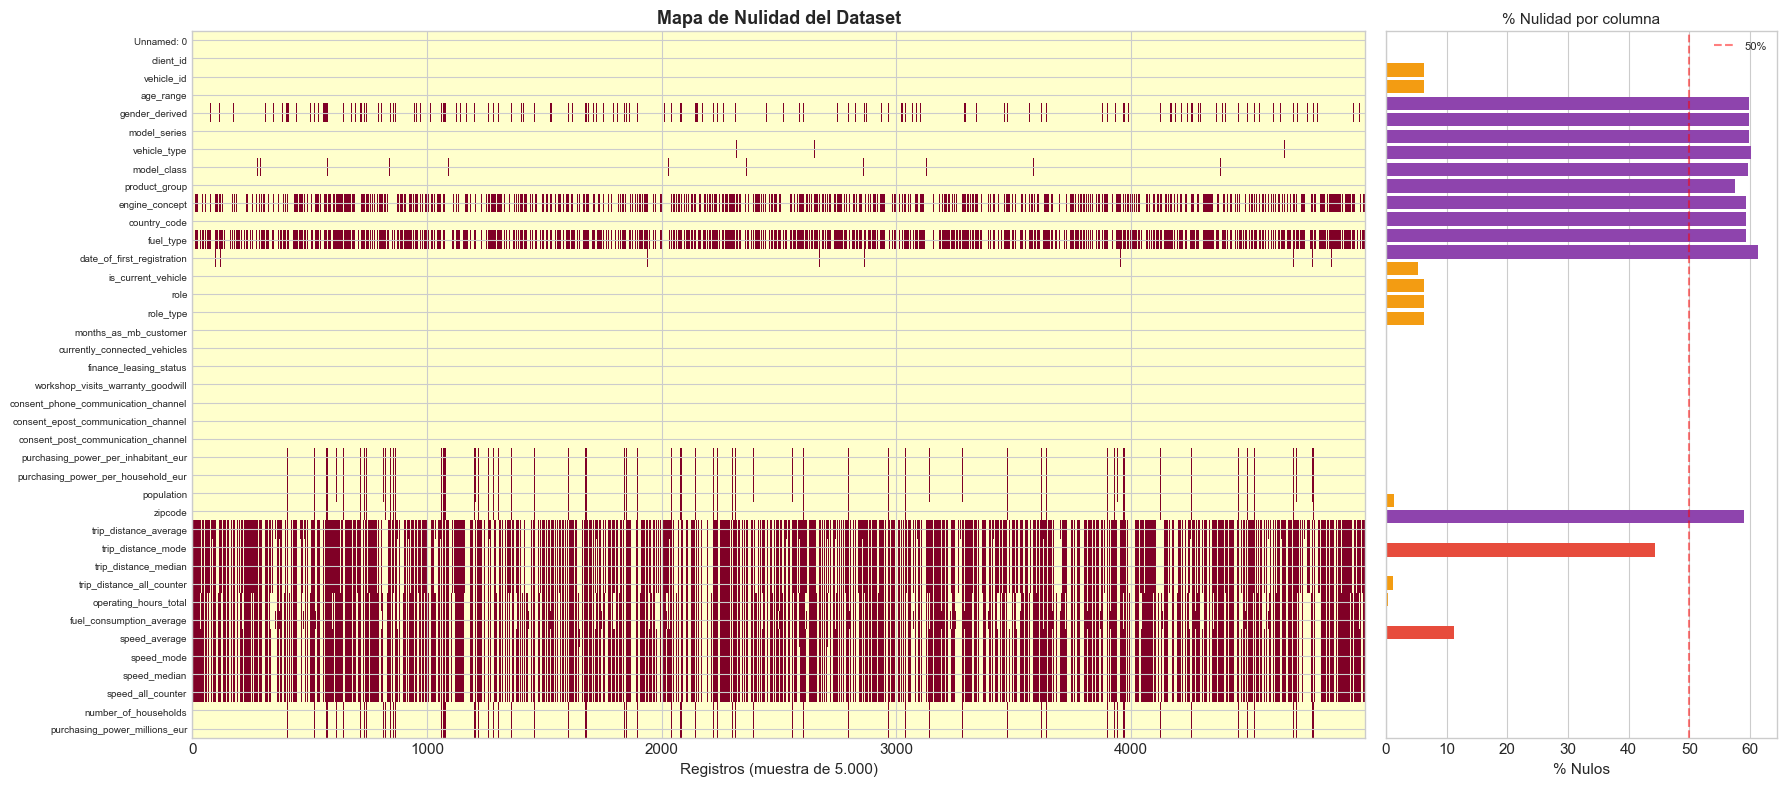

Guardado: figures/fig_01_null_heatmap.png


In [23]:
# Tomamos una muestra de 5000 registros para que el heatmap sea legible
sample = df_raw.sample(min(5000, len(df_raw)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(18, 8),
                         gridspec_kw={'width_ratios': [3, 1]})

# Heatmap de nulidad
ax1 = axes[0]
nulls_matrix = sample.isnull().astype(int)
ax1.imshow(nulls_matrix.values.T, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax1.set_yticks(range(len(df_raw.columns)))
ax1.set_yticklabels(df_raw.columns, fontsize=7)
ax1.set_xlabel('Registros (muestra de 5.000)')
ax1.set_title('Mapa de Nulidad del Dataset', fontsize=13, fontweight='bold')

# Barplot de porcentaje de nulos
ax2 = axes[1]
null_pct = df_raw.isnull().mean() * 100
colores = ['#2ecc71' if v == 0 else '#f39c12' if v < 10 else '#e74c3c' if v < 50 else '#8e44ad'
           for v in null_pct.values]
ax2.barh(range(len(null_pct)), null_pct.values, color=colores)
ax2.set_yticks([])
ax2.set_xlabel('% Nulos')
ax2.set_title('% Nulidad por columna', fontsize=11)
ax2.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50%')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('figures/fig_01_null_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: figures/fig_01_null_heatmap.png')

Observando los gráficos generados vemos en qué características se concentran los nulos, los detallamos en la siguiente sección. Además, notamos que tenemos gran parte de las características que NO tienen ningún nulo, lo cual es muy beneficioso. 

Para tener una referencia clara, generamos una tabla con todas las columnas ordenadas por
porcentaje de nulos, junto con el tipo de dato y el numero de valores unicos.

In [24]:
null_report = pd.DataFrame({
    'Columna': df_raw.columns,
    'Nulos': df_raw.isnull().sum().values,
    'Pct_Nulos': (df_raw.isnull().sum().values / len(df_raw) * 100).round(2),
    'Tipo': df_raw.dtypes.values,
    'Unicos': df_raw.nunique().values
}).sort_values('Pct_Nulos', ascending=False)

print('MAPA COMPLETO DE NULIDAD')
print('=' * 80)
for _, row in null_report.iterrows():
    barra = '#' * int(row['Pct_Nulos'] / 2)
    print(f"  {row['Columna']:<42} {row['Nulos']:>7,} ({row['Pct_Nulos']:>5.1f}%) {barra}")

MAPA COMPLETO DE NULIDAD
  trip_distance_average                      185,857 ( 61.4%) ##############################
  speed_average                              182,382 ( 60.2%) ##############################
  speed_all_counter                          181,159 ( 59.8%) #############################
  speed_mode                                 181,159 ( 59.8%) #############################
  speed_median                               181,159 ( 59.8%) #############################
  fuel_consumption_average                   180,725 ( 59.7%) #############################
  trip_distance_all_counter                  179,830 ( 59.4%) #############################
  trip_distance_median                       179,830 ( 59.4%) #############################
  trip_distance_mode                         179,830 ( 59.4%) #############################
  fuel_type                                  178,745 ( 59.0%) #############################
  operating_hours_total                      174,358 

### 4.2 Analisis del patron de nulidad en telemetria

Un patron muy llamativo es que las variables de telemetria (trip_distance, speed, fuel_consumption,
operating_hours) tienen todas entre un 57% y un 61% de nulos. Esto no parece aleatorio.

Vamos a investigar si la nulidad esta relacionada con alguna otra variable del dataset,
como por ejemplo si el vehiculo esta actualmente conectado o si es el vehiculo actual del cliente.

In [25]:
# Relacion entre nulidad de telemetria y si el vehiculo es el actual
print('Porcentaje de nulos en trip_distance_average segun is_current_vehicle:')
print(df_raw.groupby('is_current_vehicle')['trip_distance_average'].apply(
    lambda x: f"{x.isnull().mean()*100:.1f}%"
))

print()

# Relacion con currently_connected_vehicles
print('Porcentaje de nulos en trip_distance_average segun currently_connected_vehicles:')
print(df_raw.groupby('currently_connected_vehicles')['trip_distance_average'].apply(
    lambda x: f"{x.isnull().mean()*100:.1f}%"
).head(10))

Porcentaje de nulos en trip_distance_average segun is_current_vehicle:
is_current_vehicle
False    74.3%
True     52.6%
Name: trip_distance_average, dtype: str

Porcentaje de nulos en trip_distance_average segun currently_connected_vehicles:
currently_connected_vehicles
0    74.1%
1    57.4%
2    65.0%
3    69.7%
4    68.6%
5    69.8%
6    69.1%
7    64.7%
8    59.0%
9    62.4%
Name: trip_distance_average, dtype: str


Queda bastante claro que los nulos de telemetria no son un error de la base de datos. Son vehiculos
que **no tienen activado el modulo de conectividad** que se encarga de enviar estos datos. Los vehiculos que ya no
son el vehiculo actual del cliente tienen un 74% de nulos en telemetria (debido a desvinculación de cuenta por venta o fin de contrato), frente al 52% de los actuales.

Esto es un dato de negocio muy valioso que tendremos en cuenta mas adelante.

### 4.3 Analisis de nulidad en variables socioeconomicas

Las variables socioeconomicas (purchasing_power, population, etc.) tienen alrededor de un 6% de nulos.
Veamos si los nulos coinciden entre ellas, es decir, si siempre faltan juntos.

In [26]:
demo_cols = ['zipcode', 'population', 'number_of_households',
             'purchasing_power_per_inhabitant_eur',
             'purchasing_power_per_household_eur',
             'purchasing_power_millions_eur']

print('Filas donde TODAS las variables socioeconomicas son nulas:', 
      df_raw[demo_cols].isnull().all(axis=1).sum())
print('Filas donde zipcode es nulo:', df_raw['zipcode'].isnull().sum())
print('Filas donde population es nulo:', df_raw['population'].isnull().sum())
print('Filas donde purchasing_power_per_inhabitant es nulo:',
      df_raw['purchasing_power_per_inhabitant_eur'].isnull().sum())

Filas donde TODAS las variables socioeconomicas son nulas: 16135
Filas donde zipcode es nulo: 16135
Filas donde population es nulo: 19014
Filas donde purchasing_power_per_inhabitant es nulo: 19087


Los 16.135 registros sin zipcode tambien carecen de todas las demas variables socioeconomicas,
lo cual tiene sentido: si no se conoce el codigo postal, no se puede calcular nada de su zona.
Hay unos 2.879 registros adicionales (19.014 - 16.135) donde falta population pero si hay zipcode,
probablemente porque ese codigo postal no esta en la tabla de referencia.

---
## 5. Deteccion de multicolinealidad

Antes de decidir que columnas conservamos, necesitamos ver si hay variables que esten
altamente correlacionadas entre si. Si dos variables miden practicamente lo mismo,
una de las dos sobra (y de hecho puede perjudicar al modelo de clustering posterior,
porque le da doble peso a esa dimension).

### 5.1 Matriz de correlacion

In [27]:
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns
numeric_cols = [c for c in numeric_cols if c != 'Unnamed: 0']

corr = df_raw[numeric_cols].corr()

# Buscamos pares con correlacion alta
print('PARES CON CORRELACION |r| > 0.85:')
print('-' * 90)
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]
        if abs(r) > 0.85:
            print(f'  {corr.columns[i]:<40} <-> {corr.columns[j]:<40} r={r:.3f}')

PARES CON CORRELACION |r| > 0.85:
------------------------------------------------------------------------------------------
  purchasing_power_per_inhabitant_eur      <-> purchasing_power_per_household_eur       r=0.975
  population                               <-> number_of_households                     r=0.998
  population                               <-> purchasing_power_millions_eur            r=0.962
  speed_average                            <-> speed_median                             r=0.877
  number_of_households                     <-> purchasing_power_millions_eur            r=0.962


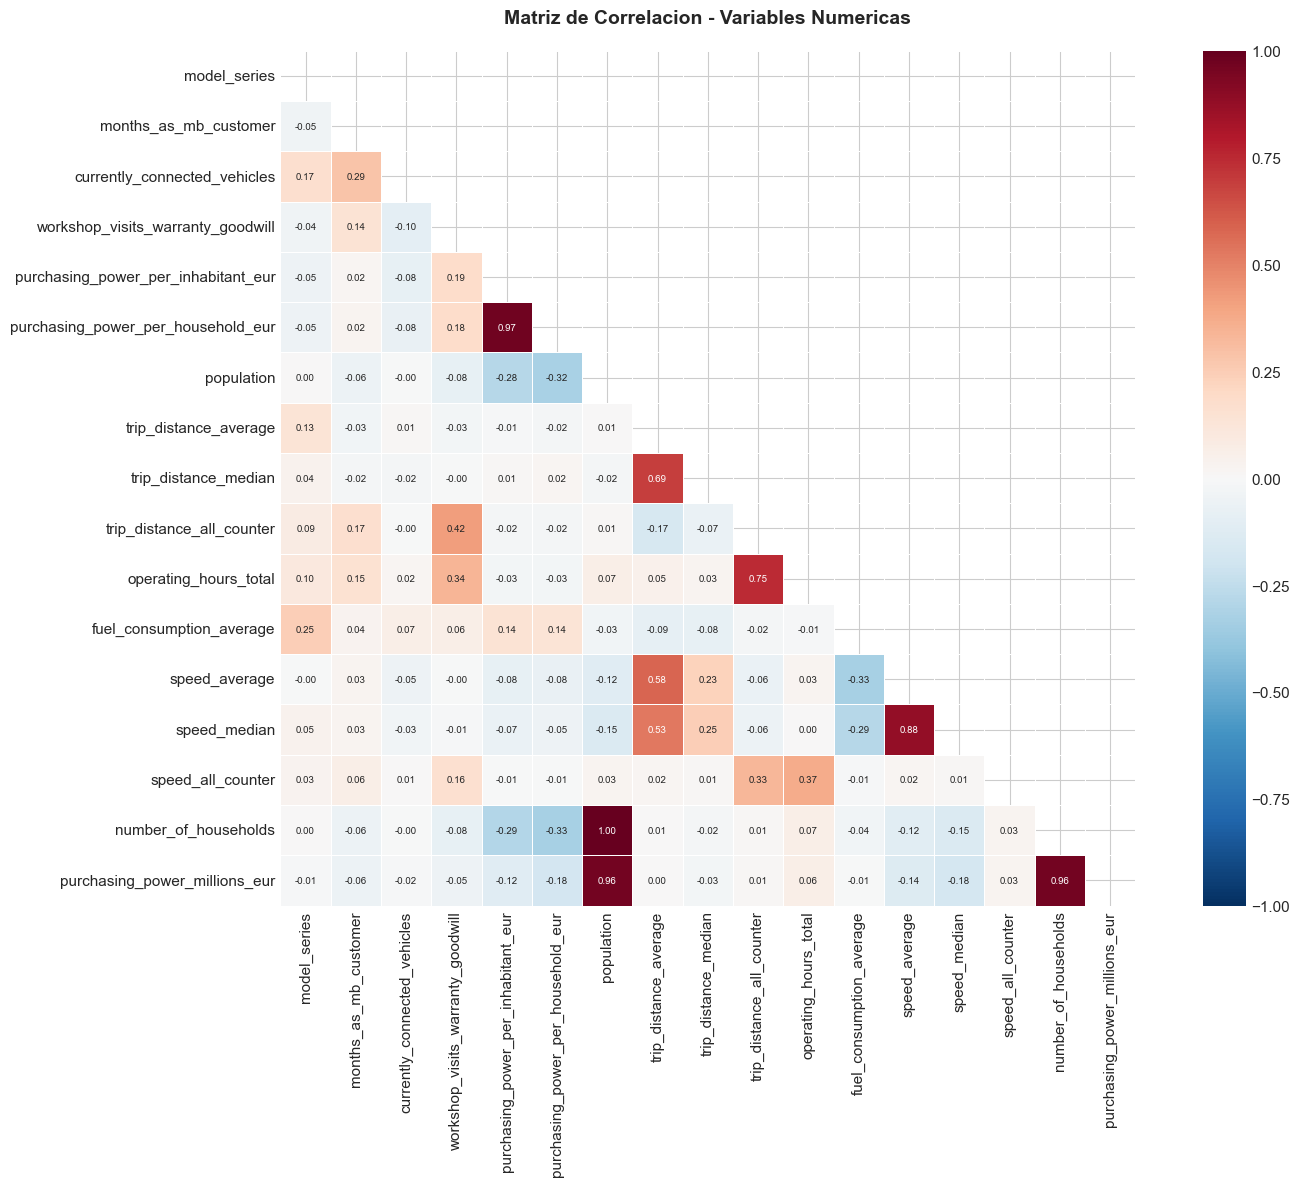

Guardado: figures/fig_02_correlation_matrix.png


In [28]:
# Heatmap de la matriz de correlacion
fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title('Matriz de Correlacion - Variables Numericas', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('figures/fig_02_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: figures/fig_02_correlation_matrix.png')

Los hallazgos mas importantes de la matriz de correlacion son:

| Par de variables | Correlacion | Implicacion |
|:-----------------|:-----------:|:------------|
| `population` y `number_of_households` | **1.00** | Son practicamente la misma variable. Hay que eliminar una. |
| `purchasing_power_per_inhabitant_eur` y `per_household_eur` | **0.97** | Misma informacion a distinta escala. Nos quedamos con una. |
| `purchasing_power_millions_eur` y `population` | **0.96** | Es un derivado (poblacion x renta per capita). Redundante. |
| `speed_median` y `speed_average` | **0.88** | Miden lo mismo de forma ligeramente distinta. |
| `trip_distance_all_counter` y `operating_hours_total` | **0.75** | Relacion logica: a mas km, mas horas. |

---
## 6. Distribuciones de variables clave

Vamos a visualizar las distribuciones de las variables mas importantes por bloque tematico.

### 6.1 Perfil demografico del cliente

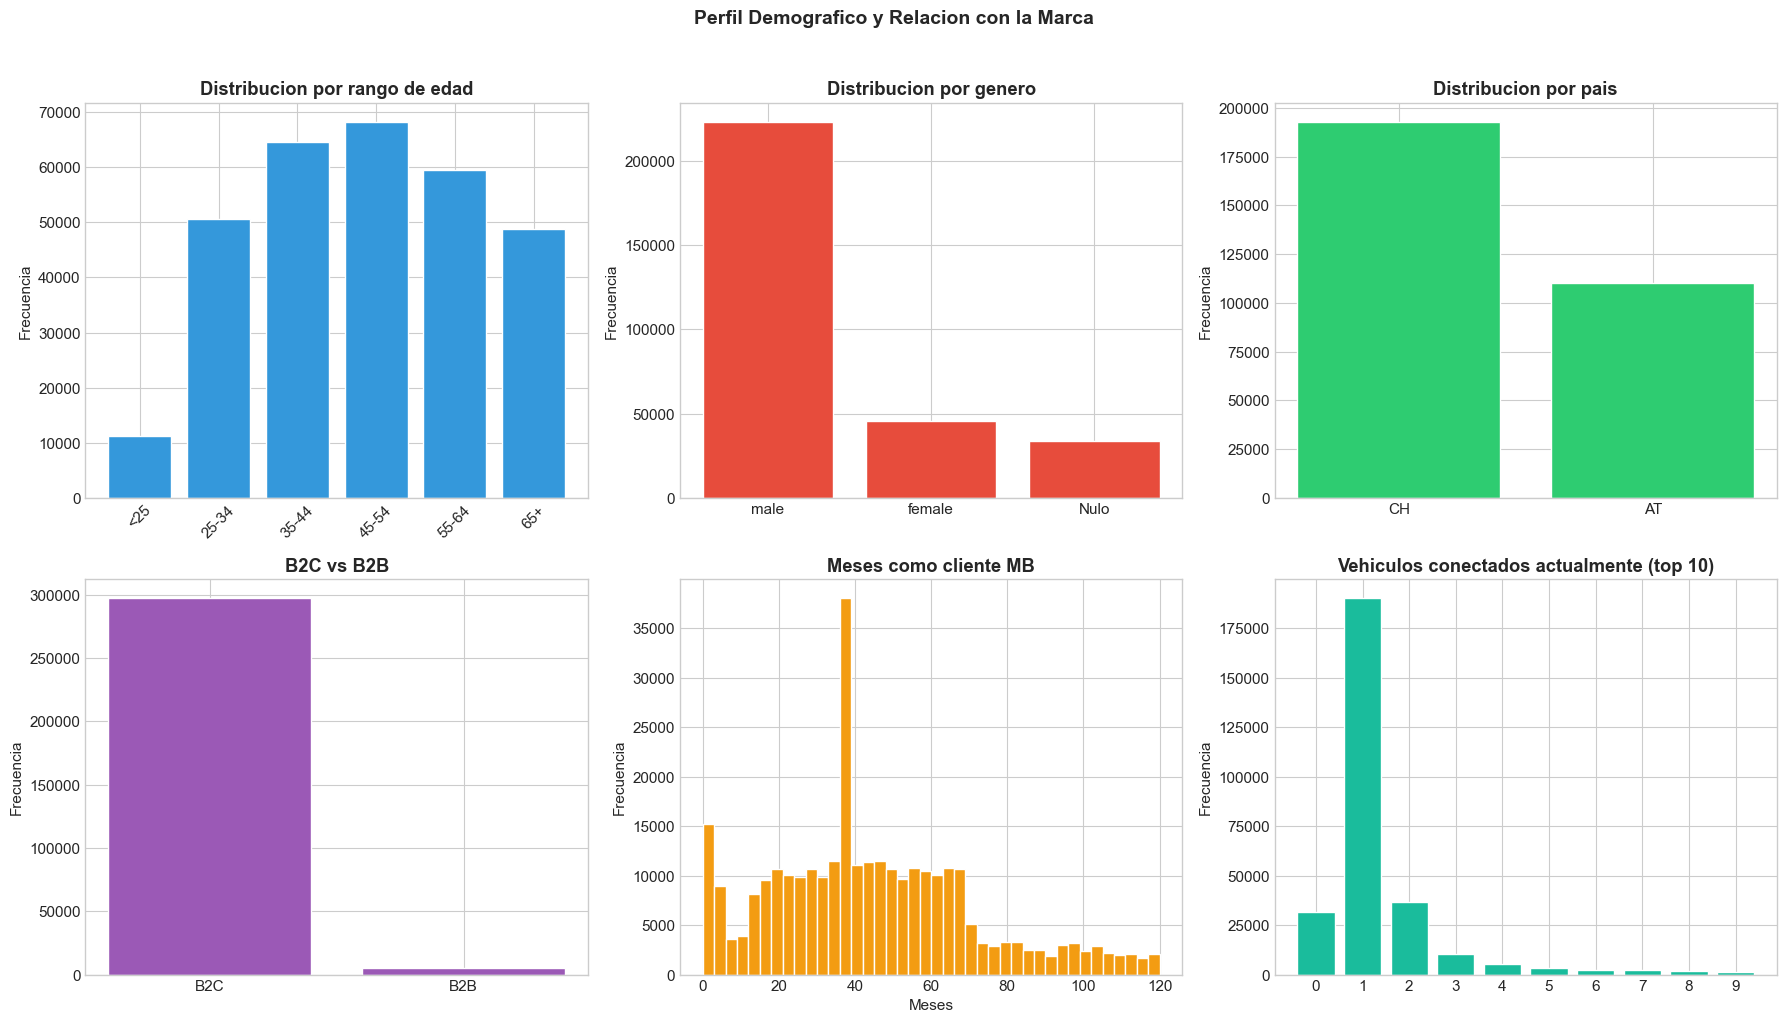

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# age_range
orden_edad = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
edad_counts = df_raw['age_range'].value_counts().reindex(orden_edad)
axes[0, 0].bar(edad_counts.index, edad_counts.values, color='#3498db', edgecolor='white')
axes[0, 0].set_title('Distribucion por rango de edad', fontweight='bold')
axes[0, 0].set_ylabel('Frecuencia')
axes[0, 0].tick_params(axis='x', rotation=45)

# gender_derived
gender_counts = df_raw['gender_derived'].value_counts(dropna=False)
gender_labels = [str(x) if pd.notna(x) else 'Nulo' for x in gender_counts.index]
axes[0, 1].bar(gender_labels, gender_counts.values, color='#e74c3c', edgecolor='white')
axes[0, 1].set_title('Distribucion por genero', fontweight='bold')
axes[0, 1].set_ylabel('Frecuencia')

# country_code
cc_counts = df_raw['country_code'].value_counts()
axes[0, 2].bar(cc_counts.index, cc_counts.values, color='#2ecc71', edgecolor='white')
axes[0, 2].set_title('Distribucion por pais', fontweight='bold')
axes[0, 2].set_ylabel('Frecuencia')

# role_type
rt_counts = df_raw['role_type'].value_counts()
axes[1, 0].bar(rt_counts.index, rt_counts.values, color='#9b59b6', edgecolor='white')
axes[1, 0].set_title('B2C vs B2B', fontweight='bold')
axes[1, 0].set_ylabel('Frecuencia')

# months_as_mb_customer
axes[1, 1].hist(df_raw['months_as_mb_customer'].dropna(), bins=40, color='#f39c12', edgecolor='white')
axes[1, 1].set_title('Meses como cliente MB', fontweight='bold')
axes[1, 1].set_xlabel('Meses')
axes[1, 1].set_ylabel('Frecuencia')

# currently_connected_vehicles
ccv = df_raw['currently_connected_vehicles'].value_counts().sort_index().head(10)
axes[1, 2].bar([str(int(x)) if pd.notna(x) else 'Nulo' for x in ccv.index], ccv.values, color='#1abc9c', edgecolor='white')
axes[1, 2].set_title('Vehiculos conectados actualmente (top 10)', fontweight='bold')
axes[1, 2].set_ylabel('Frecuencia')

plt.suptitle('Perfil Demografico y Relacion con la Marca', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_03_perfil_demografico.png', dpi=150, bbox_inches='tight')
plt.show()


### 6.2 Caracteristicas del vehiculo

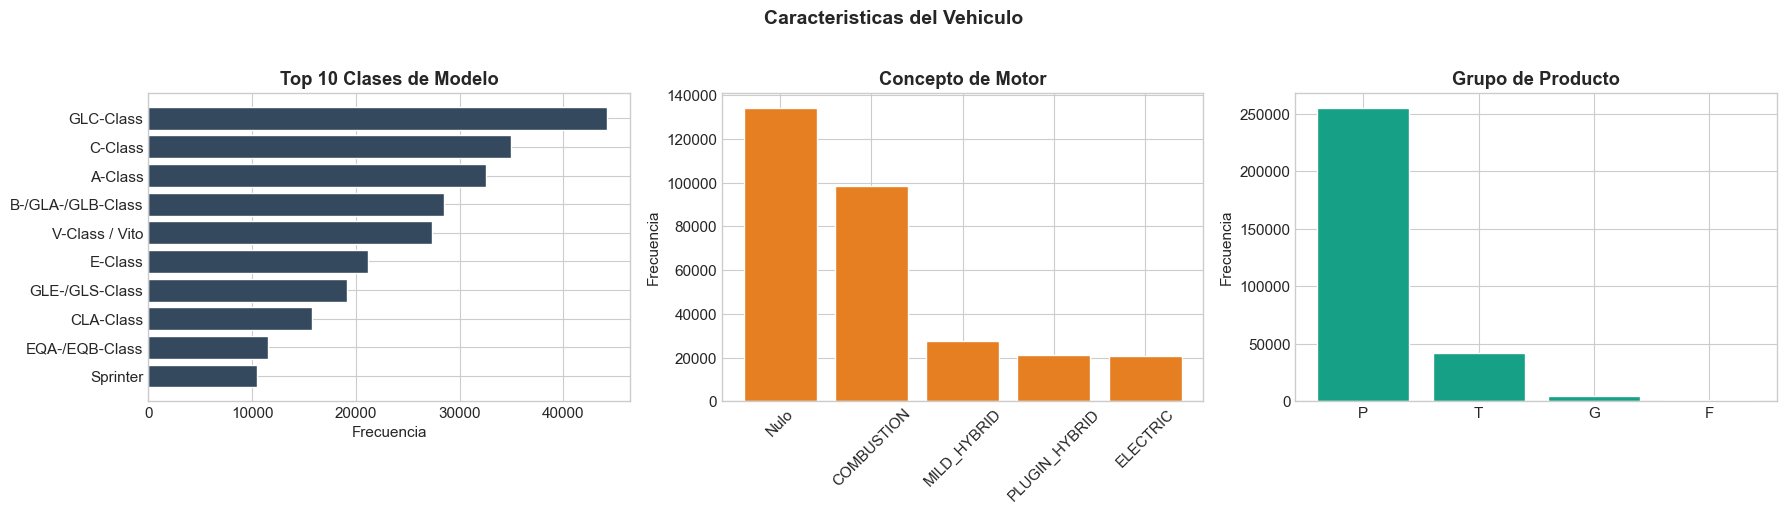

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Top 10 model_class
mc = df_raw['model_class'].value_counts().head(10)
axes[0].barh(mc.index[::-1], mc.values[::-1], color='#34495e', edgecolor='white')
axes[0].set_title('Top 10 Clases de Modelo', fontweight='bold')
axes[0].set_xlabel('Frecuencia')

# engine_concept
ec = df_raw['engine_concept'].value_counts(dropna=False)
ec_labels = [str(x) if pd.notna(x) else 'Nulo' for x in ec.index]
axes[1].bar(ec_labels, ec.values, color='#e67e22', edgecolor='white')
axes[1].set_title('Concepto de Motor', fontweight='bold')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=45)

# product_group
pg = df_raw['product_group'].value_counts()
axes[2].bar(pg.index, pg.values, color='#16a085', edgecolor='white')
axes[2].set_title('Grupo de Producto', fontweight='bold')
axes[2].set_ylabel('Frecuencia')

plt.suptitle('Caracteristicas del Vehiculo', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_04_vehiculo.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.3 Variables socioeconomicas

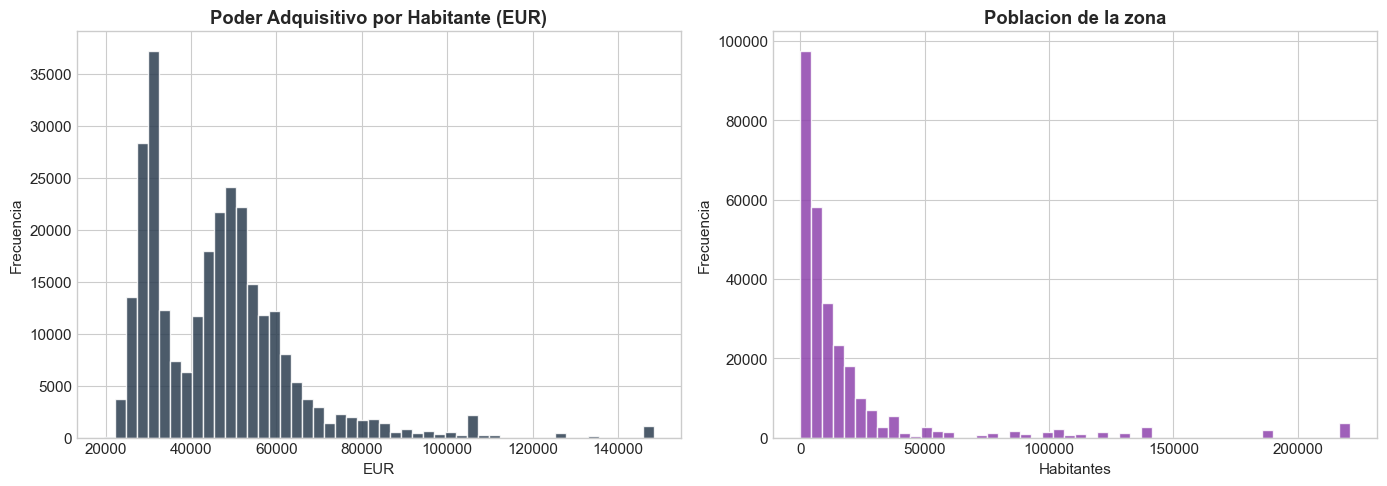

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_raw['purchasing_power_per_inhabitant_eur'].dropna(), bins=50,
             color='#2c3e50', edgecolor='white', alpha=0.85)
axes[0].set_title('Poder Adquisitivo por Habitante (EUR)', fontweight='bold')
axes[0].set_xlabel('EUR')
axes[0].set_ylabel('Frecuencia')

axes[1].hist(df_raw['population'].dropna(), bins=50,
             color='#8e44ad', edgecolor='white', alpha=0.85)
axes[1].set_title('Poblacion de la zona', fontweight='bold')
axes[1].set_xlabel('Habitantes')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig('figures/fig_05_socioeconomico.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.4 Variables de telemetria

Aunque tienen un porcentaje alto de nulos, vale la pena ver la distribucion de los valores que si tenemos.

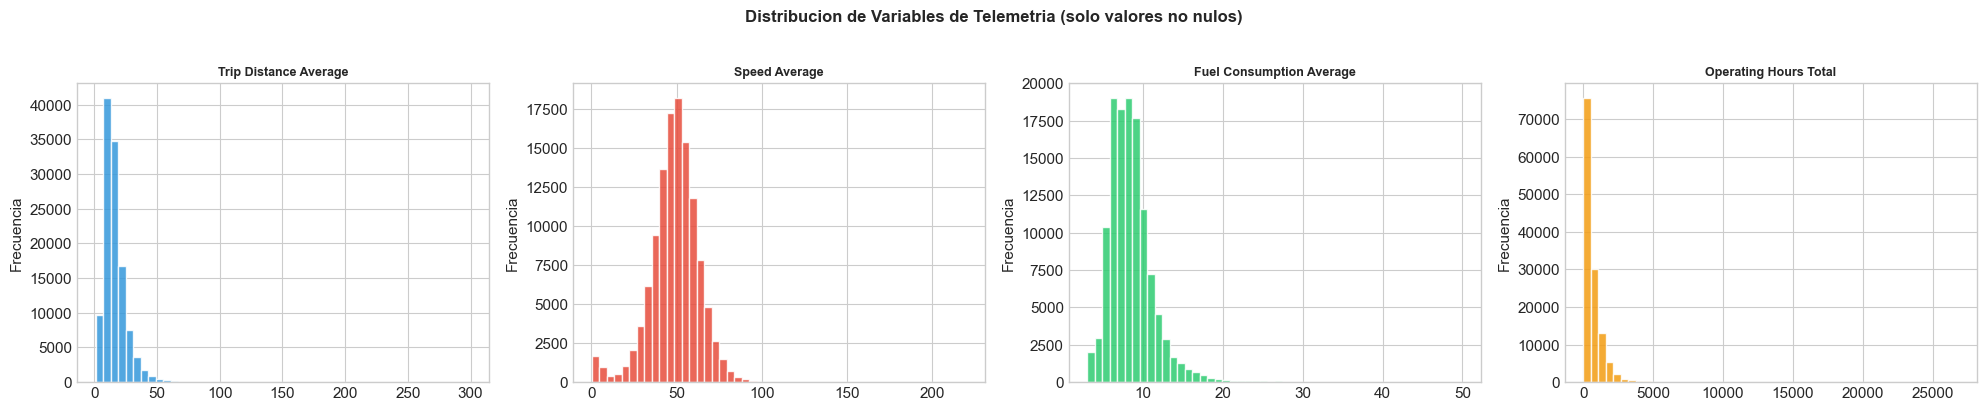

In [32]:
tele_cols = ['trip_distance_average', 'speed_average', 'fuel_consumption_average', 'operating_hours_total']

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
colores = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']

for ax, col, color in zip(axes, tele_cols, colores):
    datos = df_raw[col].dropna()
    ax.hist(datos, bins=50, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(col.replace('_', ' ').title(), fontsize=9, fontweight='bold')
    ax.set_ylabel('Frecuencia')

plt.suptitle('Distribucion de Variables de Telemetria (solo valores no nulos)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_06_telemetria.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Identificacion y exclusion de columnas sin valor analitico

Tras el analisis anterior, vamos a eliminar las columnas que no aportan valor para el analisis
o para el clustering posterior. Las razones para eliminar cada una se documentan a continuacion.

### 7.1 Columnas a eliminar

| Columna | Razon de eliminacion |
|---------|---------------------|
| `Unnamed: 0` | Indice auto-generado por el CSV, sin ningun valor analitico |
| `client_id` | Hash identificador del cliente. Tiene 173.456 valores unicos, no es una feature |
| `vehicle_id` | Hash identificador del vehiculo. 244.519 valores unicos, no es una feature |
| `zipcode` | Codigo postal con 8.284 valores unicos. Granularidad excesiva para clustering. Ya tenemos `country_code` + variables socioeconomicas que resumen la zona |
| `number_of_households` | Correlacion perfecta (1.00) con `population`. Es informacion duplicada |
| `purchasing_power_per_household_eur` | Correlacion 0.97 con `purchasing_power_per_inhabitant_eur`. Nos quedamos con la version per capita que es mas interpretable |
| `purchasing_power_millions_eur` | Correlacion 0.96 con `population`. Es un derivado (poblacion x renta) |
| `fuel_type` | 59% de nulos y ademas es redundante con `engine_concept` (que clasifica mejor el tipo de motor) |
| `speed_mode` | Texto sucio con listas concatenadas de valores (ej: "0.125,10.0625,30,50,75,110"). No se puede usar directamente |
| `trip_distance_mode` | Mismo problema que speed_mode: texto con multiples valores concatenados |
| `speed_average` | Correlacion 0.88 con `speed_median`. Preferimos la mediana por ser mas robusta frente a outliers |
| `trip_distance_average` | Correlacion 0.69 con `trip_distance_median`. Misma logica: preferimos mediana |
| `speed_all_counter` | Contador interno acumulado sin interpretabilidad clara para negocio |
| `trip_distance_all_counter` | Idem. Es un acumulado de km totales dificil de interpretar directamente |

In [33]:
COLUMNS_TO_DROP = [
    'Unnamed: 0',                          # Indice sin valor
    'client_id',                           # Hash identificador
    'vehicle_id',                          # Hash identificador
    'zipcode',                             # Granularidad excesiva
    'number_of_households',                # corr=1.00 con population
    'purchasing_power_per_household_eur',   # corr=0.97 con per_inhabitant
    'purchasing_power_millions_eur',        # corr=0.96 con population
    'fuel_type',                           # 59% nulos, redundante con engine_concept
    'speed_mode',                          # Texto sucio no parseable
    'trip_distance_mode',                  # Texto sucio no parseable
    'speed_average',                       # Preferimos speed_median (mas robusta)
    'trip_distance_average',               # Preferimos trip_distance_median
    'speed_all_counter',                   # Contador interno
    'trip_distance_all_counter',           # Contador interno
]

existing = [c for c in COLUMNS_TO_DROP if c in df_raw.columns]
df = df_raw.drop(columns=existing).copy()

print('ELIMINACION DE COLUMNAS')
print('=' * 60)
print(f'  Columnas eliminadas: {len(existing)}')
print(f'  Dimensiones resultantes: {df.shape[0]:,} x {df.shape[1]}')
print(f'  Columnas conservadas: {list(df.columns)}')

ELIMINACION DE COLUMNAS
  Columnas eliminadas: 14
  Dimensiones resultantes: 302,850 x 25
  Columnas conservadas: ['age_range', 'gender_derived', 'model_series', 'vehicle_type', 'model_class', 'product_group', 'engine_concept', 'country_code', 'date_of_first_registration', 'is_current_vehicle', 'role', 'role_type', 'months_as_mb_customer', 'currently_connected_vehicles', 'finance_leasing_status', 'workshop_visits_warranty_goodwill', 'consent_phone_communication_channel', 'consent_epost_communication_channel', 'consent_post_communication_channel', 'purchasing_power_per_inhabitant_eur', 'population', 'trip_distance_median', 'operating_hours_total', 'fuel_consumption_average', 'speed_median']


---
## 8. Propuesta de tratamiento de nulos

Ahora que hemos eliminado las columnas innecesarias, veamos que nulos nos quedan y como los tratamos.

### 8.1 Estado actual de nulos tras la limpieza de columnas

In [34]:
null_check = df.isnull().sum()
null_check = null_check[null_check > 0].sort_values(ascending=False)

print('Columnas con nulos pendientes de tratar:')
print('-' * 60)
for col, count in null_check.items():
    pct = count / len(df) * 100
    print(f'  {col:<42} {count:>7,} ({pct:>5.1f}%)')

print(f'\nTotal de columnas con nulos: {len(null_check)} de {df.shape[1]}')

Columnas con nulos pendientes de tratar:
------------------------------------------------------------
  speed_median                               181,159 ( 59.8%)
  fuel_consumption_average                   180,725 ( 59.7%)
  trip_distance_median                       179,830 ( 59.4%)
  operating_hours_total                      174,358 ( 57.6%)
  engine_concept                             134,390 ( 44.4%)
  gender_derived                              33,923 ( 11.2%)
  purchasing_power_per_inhabitant_eur         19,087 (  6.3%)
  population                                  19,014 (  6.3%)
  date_of_first_registration                   4,182 (  1.4%)
  model_class                                  3,369 (  1.1%)
  vehicle_type                                   922 (  0.3%)
  months_as_mb_customer                            4 (  0.0%)

Total de columnas con nulos: 12 de 25


### 8.2 Estrategia de imputacion para cada columna

La estrategia que seguimos es:

**Variables categoricas con pocos nulos (< 2%): imputacion por moda jerarquica**
- `model_class` (1.1% nulos): la imputamos con la moda agrupada por `model_series`, porque en Mercedes cada series tiene una clase de modelo predominante.
- `vehicle_type` (0.3% nulos): la imputamos con la moda por `model_series`.

**Variables categoricas con nulos moderados:**
- `engine_concept` (44% nulos): la imputamos con la moda por `vehicle_type` x `model_series`. Esto funciona porque la combinacion modelo+tipo determina en gran medida el motor.
- `gender_derived` (11% nulos): usamos logica de negocio. Los registros B2B (empresas) sin genero los marcamos como 'Company'. El resto como 'Unknown'.

**Variables numericas con pocos nulos:**
- `months_as_mb_customer` (4 nulos): mediana global. Son tan pocos que da igual.
- `date_of_first_registration` (1.4%): la convertimos a antiguedad en anios e imputamos con la mediana por `model_series`.
- `purchasing_power_per_inhabitant_eur` y `population` (~6%): mediana agrupada por `country_code` x `model_class`.

**Variables de telemetria (~60% nulos):**
- Creamos un flag `has_telemetry_active` (0/1) que indica si el vehiculo tiene telemetria.
- Imputamos los nulos con la mediana por segmento para que el modelo de clustering tenga valores numericos, pero el flag permite distinguir valores reales de imputados.

In [35]:
# Funcion auxiliar para imputacion categorica por moda agrupada
def imputar_moda_por_grupo(df, target_col, group_cols, fallback='Unknown'):
    """Imputa nulos de una columna categorica usando la moda agrupada."""
    nulls_antes = df[target_col].isnull().sum()
    if nulls_antes == 0:
        print(f'  {target_col}: sin nulos, no se necesita imputacion')
        return df
    
    # Calcular la moda por grupo
    mode_map = (
        df.dropna(subset=[target_col])
        .groupby(group_cols)[target_col]
        .agg(lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else fallback)
        .reset_index()
        .rename(columns={target_col: '_valor_imputado'})
    )
    
    df = df.merge(mode_map, on=group_cols, how='left')
    mask = df[target_col].isnull()
    df.loc[mask, target_col] = df.loc[mask, '_valor_imputado']
    df = df.drop(columns=['_valor_imputado'])
    
    # Rellenar restantes con fallback
    restantes = df[target_col].isnull().sum()
    if restantes > 0:
        df[target_col] = df[target_col].fillna(fallback)
    
    nulls_despues = df[target_col].isnull().sum()
    rescatados = nulls_antes - nulls_despues
    print(f'  {target_col}: {nulls_antes:,} nulos -> {nulls_despues:,} (rescatados: {rescatados:,})')
    return df


# Funcion auxiliar para imputacion numerica por mediana agrupada
def imputar_mediana_por_grupo(df, target_col, group_cols):
    """Imputa nulos de una columna numerica usando la mediana agrupada."""
    nulls_antes = df[target_col].isnull().sum()
    if nulls_antes == 0:
        print(f'  {target_col}: sin nulos')
        return df
    
    mediana_grupo = df.groupby(group_cols)[target_col].transform('median')
    df[target_col] = df[target_col].fillna(mediana_grupo)
    
    # Fallback con mediana global
    restantes = df[target_col].isnull().sum()
    if restantes > 0:
        df[target_col] = df[target_col].fillna(df[target_col].median())
    
    nulls_despues = df[target_col].isnull().sum()
    rescatados = nulls_antes - nulls_despues
    print(f'  {target_col}: {nulls_antes:,} nulos -> {nulls_despues:,} (rescatados: {rescatados:,})')
    return df


print('IMPUTACION DE NULOS')
print('=' * 70)

IMPUTACION DE NULOS


In [36]:
# --- model_class (1.1% nulos) -> moda por model_series ---
print('\nmodel_class (moda por model_series):')
df = imputar_moda_por_grupo(df, 'model_class', ['model_series'], fallback='Unknown')

# --- vehicle_type (0.3% nulos) -> moda por model_series ---
print('\nvehicle_type (moda por model_series):')
df = imputar_moda_por_grupo(df, 'vehicle_type', ['model_series'], fallback='Unknown')

# --- engine_concept (44% nulos) -> moda por vehicle_type x model_series ---
print('\nengine_concept (moda por vehicle_type x model_series):')
df = imputar_moda_por_grupo(df, 'engine_concept', ['vehicle_type', 'model_series'], fallback='Unknown')

# --- gender_derived (11% nulos) -> logica de negocio ---
print('\ngender_derived (logica de negocio B2B/B2C):')
nulls_antes_gender = df['gender_derived'].isnull().sum()
df.loc[(df['gender_derived'].isnull()) & (df['role_type'] == 'B2B'), 'gender_derived'] = 'Company'
df.loc[df['gender_derived'].isnull(), 'gender_derived'] = 'Unknown'
print(f'  gender_derived: {nulls_antes_gender:,} nulos -> {df["gender_derived"].isnull().sum()} (B2B->Company, B2C->Unknown)')


model_class (moda por model_series):
  model_class: 3,369 nulos -> 0 (rescatados: 3,369)

vehicle_type (moda por model_series):
  vehicle_type: 922 nulos -> 0 (rescatados: 922)

engine_concept (moda por vehicle_type x model_series):
  engine_concept: 134,390 nulos -> 0 (rescatados: 134,390)

gender_derived (logica de negocio B2B/B2C):
  gender_derived: 33,923 nulos -> 0 (B2B->Company, B2C->Unknown)


In [37]:
# --- Variables socioeconomicas -> mediana por country_code x model_class ---
print('\nVariables socioeconomicas (mediana por country_code x model_class):')
df = imputar_mediana_por_grupo(df, 'purchasing_power_per_inhabitant_eur', ['country_code', 'model_class'])
df = imputar_mediana_por_grupo(df, 'population', ['country_code', 'model_class'])

# --- months_as_mb_customer (4 nulos) -> mediana global ---
print('\nmonths_as_mb_customer (mediana global, solo 4 nulos):')
nulls_months = df['months_as_mb_customer'].isnull().sum()
df['months_as_mb_customer'] = df['months_as_mb_customer'].fillna(df['months_as_mb_customer'].median())
print(f'  months_as_mb_customer: {nulls_months} nulos -> 0 (mediana global)')


Variables socioeconomicas (mediana por country_code x model_class):
  purchasing_power_per_inhabitant_eur: 19,087 nulos -> 0 (rescatados: 19,087)
  population: 19,014 nulos -> 0 (rescatados: 19,014)

months_as_mb_customer (mediana global, solo 4 nulos):
  months_as_mb_customer: 4 nulos -> 0 (mediana global)


In [38]:
# --- date_of_first_registration (1.4%) -> convertir a fecha y calcular antiguedad ---
print('\ndate_of_first_registration (conversion a fecha + imputacion de antiguedad):')
df['date_of_first_registration'] = pd.to_datetime(df['date_of_first_registration'], errors='coerce')
nulls_date = df['date_of_first_registration'].isnull().sum()
print(f'  Nulos tras conversion a fecha: {nulls_date:,}')

# Calcular antiguedad en dias para poder imputar numericamente
df['_vehicle_age_days'] = (REFERENCE_DATE - df['date_of_first_registration']).dt.days

# Imputar la antiguedad en dias por la mediana de su model_series
median_age = df.groupby('model_series')['_vehicle_age_days'].transform('median')
df['_vehicle_age_days'] = df['_vehicle_age_days'].fillna(median_age)
df['_vehicle_age_days'] = df['_vehicle_age_days'].fillna(df['_vehicle_age_days'].median())  # fallback global

# Reconstruir la fecha para los que tenian nulos
mask_null_date = df['date_of_first_registration'].isnull()
df.loc[mask_null_date, 'date_of_first_registration'] = (
    REFERENCE_DATE - pd.to_timedelta(df.loc[mask_null_date, '_vehicle_age_days'], unit='D')
)
print(f'  Reconstruidas {mask_null_date.sum():,} fechas a partir de la antiguedad media por model_series')


date_of_first_registration (conversion a fecha + imputacion de antiguedad):
  Nulos tras conversion a fecha: 4,182
  Reconstruidas 4,182 fechas a partir de la antiguedad media por model_series


In [39]:
# --- Telemetria (~60% nulos) -> flag + mediana por segmento ---
print('\nVariables de telemetria (flag de presencia + imputacion por segmento):')

# Primero creamos el flag que indica si el vehiculo tiene telemetria activa
df['has_telemetry_active'] = (~df['trip_distance_median'].isnull()).astype(int)
telemetry_pct = df['has_telemetry_active'].mean() * 100
print(f'  Creado has_telemetry_active: {telemetry_pct:.1f}% de clientes con telemetria activa')

# Ahora imputamos los nulos de las variables de telemetria
TELEMETRY_COLS = ['trip_distance_median', 'speed_median',
                  'fuel_consumption_average', 'operating_hours_total']

group_cols = ['role_type', 'country_code', 'model_class']

for col in TELEMETRY_COLS:
    nulls_antes = df[col].isnull().sum()
    pct_antes = nulls_antes / len(df) * 100
    
    # Mediana por grupo
    group_median = df.groupby(group_cols)[col].transform('median')
    df[col] = df[col].fillna(group_median)
    
    # Fallback: mediana global
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())
    
    nulls_despues = df[col].isnull().sum()
    print(f'  {col:<30} {nulls_antes:>7,} ({pct_antes:>5.1f}%) -> {nulls_despues} nulos')


Variables de telemetria (flag de presencia + imputacion por segmento):
  Creado has_telemetry_active: 40.6% de clientes con telemetria activa
  trip_distance_median           179,830 ( 59.4%) -> 0 nulos
  speed_median                   181,159 ( 59.8%) -> 0 nulos
  fuel_consumption_average       180,725 ( 59.7%) -> 0 nulos
  operating_hours_total          174,358 ( 57.6%) -> 0 nulos


### 8.3 Verificacion: cero nulos

Comprobamos que no queda ningun nulo en el dataset tras todo el tratamiento.

In [40]:
# Eliminar columna temporal
df = df.drop(columns=['_vehicle_age_days'], errors='ignore')

total_nulls = df.isnull().sum().sum()
print('VERIFICACION FINAL')
print('=' * 60)
print(f'Total de nulos en el dataset: {total_nulls}')

if total_nulls == 0:
    print('Dataset completamente limpio. No quedan nulos.')
else:
    print('Columnas con nulos residuales:')
    remaining = df.isnull().sum()
    for col, count in remaining[remaining > 0].items():
        print(f'  {col}: {count:,}')

print(f'\nDimensiones finales: {df.shape[0]:,} x {df.shape[1]}')
print(f'Columnas: {list(df.columns)}')

VERIFICACION FINAL
Total de nulos en el dataset: 0
Dataset completamente limpio. No quedan nulos.

Dimensiones finales: 302,850 x 26
Columnas: ['age_range', 'gender_derived', 'model_series', 'vehicle_type', 'model_class', 'product_group', 'engine_concept', 'country_code', 'date_of_first_registration', 'is_current_vehicle', 'role', 'role_type', 'months_as_mb_customer', 'currently_connected_vehicles', 'finance_leasing_status', 'workshop_visits_warranty_goodwill', 'consent_phone_communication_channel', 'consent_epost_communication_channel', 'consent_post_communication_channel', 'purchasing_power_per_inhabitant_eur', 'population', 'trip_distance_median', 'operating_hours_total', 'fuel_consumption_average', 'speed_median', 'has_telemetry_active']


---
## 9. Resumen de hallazgos y conclusiones

### 9.1 Principales caracteristicas de los clientes

- **Paises:** El dataset cubre clientes de Suiza (CH) y Austria (AT), siendo Suiza el mercado
  con mayor volumen de registros.
- **Tipo de cliente:** La gran mayoria son B2C (particulares). Los B2B (flotas/empresas)
  representan una fraccion muy pequena.
- **Edad:** Los rangos mas frecuentes son 35-44 y 45-54 anios. El perfil tipico del cliente
  Mercedes-Benz es de mediana edad.
- **Genero:** Predominan los hombres, pero hay un 11% de valores desconocidos (probablemente empresas
  o registros incompletos).
- **Antiguedad como cliente:** La mediana esta en torno a 39 meses (unos 3 anios), lo cual
  sugiere un ciclo de renovacion razonable.
- **Vehiculos conectados:** La mayoria de clientes tiene 1 vehiculo conectado. Hay algunos con
  flotas grandes (hasta 21).
- **Modelos mas populares:** Las clases A, C, E y GLC dominan el parque de vehiculos.

### 9.2 Problemas de calidad encontrados y como los hemos resuelto

| Problema | Detalle | Solucion aplicada |
|----------|---------|-------------------|
| **Columna indice artificial** | `Unnamed: 0` es un indice del CSV | Eliminada |
| **Identificadores hash** | `client_id` y `vehicle_id` no son features | Eliminados |
| **Multicolinealidad perfecta** | `number_of_households` y `population` tienen corr=1.00 | Eliminamos `number_of_households` |
| **Multicolinealidad alta** | Tres pares con correlacion >0.96 entre variables socioeconomicas | Conservamos solo `purchasing_power_per_inhabitant_eur` y `population` |
| **Texto sucio** | `speed_mode` y `trip_distance_mode` contienen listas concatenadas | Eliminadas |
| **60% nulos en telemetria** | No es un error: indica vehiculos sin modulo de conectividad activado | Creamos flag `has_telemetry_active` + imputacion por mediana por segmento |
| **44% nulos en engine_concept** | Falta el concepto de motor en casi la mitad de registros | Imputacion jerarquica por moda de vehicle_type x model_series |
| **11% nulos en gender_derived** | Genero desconocido | Logica de negocio: B2B->Company, resto->Unknown |
| **~6% nulos socioeconomicos** | Falta info de la zona geografica | Mediana agrupada por pais x clase de modelo |
| **Variables redundantes** | speed_average vs median, trip_distance idem | Conservamos solo medianas (mas robustas) |
| **Contadores internos** | speed_all_counter, trip_distance_all_counter | Eliminados por baja interpretabilidad de negocio |

### 9.3 Exportacion del dataset limpio

Guardamos el dataset limpio en un CSV para que el Reto 2 (Feature Engineering) pueda partir
directamente de aqui sin tener que repetir toda la limpieza.

**Importante para la compatibilidad con el Reto 2:** el fichero exportado mantiene exactamente
las mismas columnas y el mismo indice que el dataframe `df` de este notebook. El Reto 2 debe
cargar este CSV como punto de partida.

In [41]:
os.makedirs('data', exist_ok=True)
OUTPUT_PATH = 'data/reto1_dataset_limpio.csv'

df.to_csv(OUTPUT_PATH, index=False)

print(f'Dataset limpio exportado a: {OUTPUT_PATH}')
print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Tamano del fichero: {os.path.getsize(OUTPUT_PATH) / 1e6:.1f} MB')
print(f'\nColumnas exportadas ({df.shape[1]}):')
for i, col in enumerate(df.columns, 1):
    dtype = df[col].dtype
    print(f'  {i:>2}. {col:<42} ({dtype})')

Dataset limpio exportado a: data/reto1_dataset_limpio.csv
Dimensiones: 302,850 filas x 26 columnas
Tamano del fichero: 51.8 MB

Columnas exportadas (26):
   1. age_range                                  (str)
   2. gender_derived                             (str)
   3. model_series                               (int64)
   4. vehicle_type                               (str)
   5. model_class                                (str)
   6. product_group                              (str)
   7. engine_concept                             (str)
   8. country_code                               (str)
   9. date_of_first_registration                 (datetime64[us])
  10. is_current_vehicle                         (bool)
  11. role                                       (str)
  12. role_type                                  (str)
  13. months_as_mb_customer                      (float64)
  14. currently_connected_vehicles               (int64)
  15. finance_leasing_status                     (str)
 

In [42]:
# Verificacion rapida de que el CSV se puede recargar correctamente
df_check = pd.read_csv(OUTPUT_PATH)
print(f'Verificacion de recarga: {df_check.shape}')
print(f'Nulos en el fichero recargado: {df_check.isnull().sum().sum()}')
print('\nEl dataset esta listo para el Reto 2.')

Verificacion de recarga: (302850, 26)
Nulos en el fichero recargado: 0

El dataset esta listo para el Reto 2.
